In [21]:
import pandas as pd
import numpy as np


# 1. Load the Telco Customer Churn dataset from your folder path
file_path = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(file_path)

# 2. Inspect basic dimensions and structure
print(f"Dataset Shape (Rows, Columns): {df.shape}\n")

print("--- First 3 Rows Preview ---")
display(df.head(3))

print("\n--- Data Types & Non-Null Counts ---")
df.info()

Dataset Shape (Rows, Columns): (7043, 21)

--- First 3 Rows Preview ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes



--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pape

In [22]:
# 1. Inspect unique values or check for blank spaces hidden in TotalCharges object dtype
# Converting TotalCharges to numeric, forcing blank spaces to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many NaNs were created by blank spaces
print(f"Missing values in TotalCharges after coercion: {df['TotalCharges'].isnull().sum()}")

# 2. Handle Missing Values: Drop those few rows (since tenure is 0, they are brand new customers)
df = df.dropna(subset=['TotalCharges']).reset_index(drop=True)

# 3. Drop 'customerID' as it has no predictive power (unique identifier)
df = df.drop(columns=['customerID'])

# 4. Map the Target Variable ('Churn') from Yes/No to 1/0
# 1 = Churn, 0 = Non-Churn
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"Updated Dataset Shape after cleaning: {df.shape}")
print(f"Target Churn distribution:\n{df['Churn'].value_counts(normalize=True) * 100}%")

Missing values in TotalCharges after coercion: 11
Updated Dataset Shape after cleaning: (7032, 20)
Target Churn distribution:
Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64%


In [23]:
from sklearn.model_selection import train_test_split

#  1. One-Hot Encoding for all categorical variables
# get_dummies converts object/categorical columns into binary 0/1 columns
# We use drop_first=True to avoid multicollinearity (Dummy Variable Trap)
df_encoded = pd.get_dummies(df, drop_first=True)

print(f"Shape after One-Hot Encoding: {df_encoded.shape}")

# 2. Separate Features (X) and Target (y)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# 3. Train-Test Split
# We split our data into 80% training and 20% testing
# random_state ensures reproducibility so we get the exact same split every time
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set shape (X_train): {X_train.shape}")
print(f"Testing set shape (X_test): {X_test.shape}")
print(f"Training set Churn distribution:\n{y_train.value_counts(normalize=True)}")

Shape after One-Hot Encoding: (7032, 31)

Training set shape (X_train): (5625, 30)
Testing set shape (X_test): (1407, 30)
Training set Churn distribution:
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64


In [24]:
from sklearn.preprocessing import StandardScaler

# 1. Identify columns that need scaling (numerical columns with large value ranges)
# In our dataset, 'tenure', 'MonthlyCharges', and 'TotalCharges' have wide numeric ranges 
# compared to our 0/1 binary columns from one-hot encoding.
cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges']

# 2. Initialize the StandardScaler
scaler = StandardScaler()

# 3. Fit and transform the training set, then transform the test set
# CRITICAL RULE: We fit ONLY on X_train to prevent Data Leakage from the test set!
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("--- Scaled Training Data Preview ---")
display(X_train_scaled[cols_to_scale].head())

print("\nMean of scaled columns (should be ~0):")
print(X_train_scaled[cols_to_scale].mean())

print("\nStandard Deviation of scaled columns (should be 1):")
print(X_train_scaled[cols_to_scale].std())

--- Scaled Training Data Preview ---


,tenure,MonthlyCharges,TotalCharges
1408,1.321816,0.981556,1.659900
6992,-0.267410,-0.971546,-0.562252
3349,1.444064,0.837066,1.756104
4486,-1.204646,0.641092,-0.908326
3535,0.669826,-0.808787,-0.101561



Mean of scaled columns (should be ~0):
tenure           -1.291609e-16
MonthlyCharges    3.157968e-17
TotalCharges      8.842310e-18
dtype: float64

Standard Deviation of scaled columns (should be 1):
tenure            1.000089
MonthlyCharges    1.000089
TotalCharges      1.000089
dtype: float64


In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize a Baseline Model (DummyClassifier using the most frequent class)
# This mimics a naive strategy: always predicting the majority class (Non-Churn = 0)
baseline_model = DummyClassifier(strategy='most_frequent', random_state=42)

# 2. Train the baseline model on the training data
baseline_model.fit(X_train_scaled, y_train)

# 3. Predict on the test set
y_pred_baseline = baseline_model.predict(X_test_scaled)

# 4. Evaluate the baseline
print("--- Baseline Model Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

--- Baseline Model Performance ---
Accuracy: 0.7342

Classification Report:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1033
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1407
   macro avg       0.37      0.50      0.42      1407
weighted avg       0.54      0.73      0.62      1407



In [26]:
from sklearn.linear_model import LogisticRegression

# 1. Initialize the Logistic Regression model
# random_state ensures reproducibility
log_reg = LogisticRegression(random_state=42)

# 2. Train the model on our scaled training data
log_reg.fit(X_train_scaled, y_train)

# 3. Predict on the test set
y_pred_log_reg = log_reg.predict(X_test_scaled)

# 4. Evaluate Logistic Regression performance
print("--- Logistic Regression Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log_reg):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log_reg))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_log_reg))

--- Logistic Regression Performance ---
Accuracy: 0.8045

Confusion Matrix:
[[918 115]
 [160 214]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [27]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the Random Forest Classifier (Ensemble of Decision Trees)
# random_state ensures reproducibility
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Train the model on unscaled training data (Tree models don't need feature scaling)
rf_model.fit(X_train, y_train)

# 3. Predict on the unscaled test set
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate Random Forest performance
print("--- Random Forest Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

--- Random Forest Performance ---
Accuracy: 0.7896

Confusion Matrix:
[[917 116]
 [180 194]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



Logistic Regression ROC-AUC Score: 0.8361
Random Forest ROC-AUC Score:       0.8165


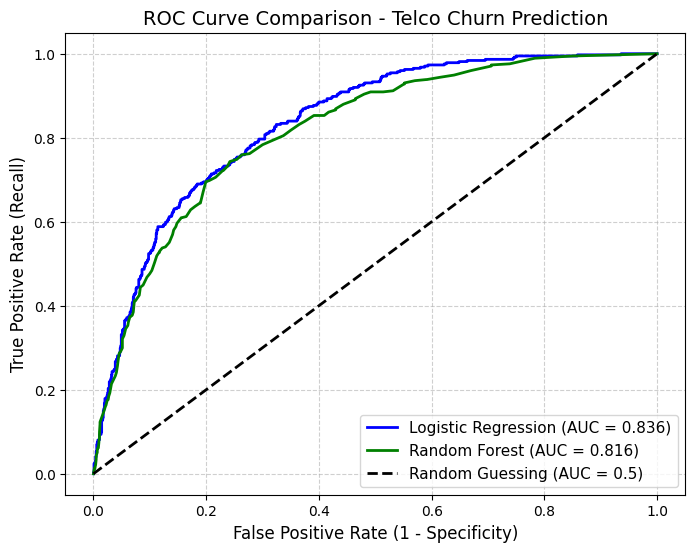

In [28]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# 1. Get predicted probabilities for Class 1 (Churn)
# Logistic Regression uses scaled data; Random Forest uses unscaled data
y_prob_log_reg = log_reg.predict_proba(X_X_scaled if 'X_X_scaled' in locals() else X_test_scaled)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# 2. Calculate ROC-AUC scores
roc_auc_lr = roc_auc_score(y_test, y_prob_log_reg)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"Logistic Regression ROC-AUC Score: {roc_auc_lr:.4f}")
print(f"Random Forest ROC-AUC Score:       {roc_auc_rf:.4f}")

# 3. Plot ROC Curves to visualize performance
plt.figure(figsize=(8, 6))

# Logistic Regression Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_log_reg)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})', color='blue', lw=2)

# Random Forest Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})', color='green', lw=2)

# Diagonal random guess line
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guessing (AUC = 0.5)')

plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve Comparison - Telco Churn Prediction', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()